In [1]:
import numpy as np

def Q1_ARForecast(s, phi):
    """
    s   : vecteur des p dernières observations
    phi : vecteur [phi0, phi1, ..., phip]

    retourne la prévision à 1 pas
    """

    s = np.asarray(s).flatten()
    phi = np.asarray(phi).flatten()

    p = len(s)

    forecast = phi[0]

    for j in range(p):
        forecast += phi[j+1] * s[p-j-1]

    return forecast

In [11]:
import pandas as pd
import numpy as np
from statsmodels.tsa.ar_model import AutoReg

df = pd.read_csv("PJM.csv")

price = df[" Zonal COMED price"]

price_2018 = price.iloc[-8760:].reset_index(drop=True)

model = AutoReg(price_2018, lags=24)
results = model.fit()

print(results.summary())

phi = results.params.values

s = price_2018.iloc[-24:].values

forecast = Q1_ARForecast(s, phi)

print("Prévision heure suivante :", forecast)

                            AutoReg Model Results                             
Dep. Variable:      Zonal COMED price   No. Observations:                 8736
Model:                    AutoReg(24)   Log Likelihood              -23507.944
Method:               Conditional MLE   S.D. of innovations              3.568
Date:                Fri, 20 Nov 2026   AIC                          47067.888
Time:                        14:53:02   BIC                          47251.843
Sample:                            24   HQIC                         47130.576
                                 8760                                         
                             coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------------------
const                      0.6172      0.139      4.428      0.000       0.344       0.890
 Zonal COMED price.L1      1.1466      0.011    108.093      0.000       1.126       1.167
 Zon

In [12]:
import numpy as np

def Q1_AREstimate(s, p):

    s = np.asarray(s).flatten()

    T = len(s)

    y = s[p:]

    X = np.ones((T - p, p + 1))

    for j in range(1, p + 1):
        X[:, j] = s[p - j:T - j]

    phi = np.linalg.inv(X.T @ X) @ (X.T @ y)

    yhat = X @ phi

    residuals = y - yhat

    return phi, residuals

In [13]:
import pandas as pd

df = pd.read_csv("PJM.csv")

df.columns = df.columns.str.strip()

price = pd.to_numeric(df["Zonal COMED price"], errors="coerce")

price_2018 = price.iloc[-8760:].values

phi, residuals = Q1_AREstimate(price_2018, 24)

print("Coefficients estimés :")
print(phi)

Coefficients estimés :
[ 6.17161737e-01  1.14655570e+00 -3.62307439e-01  4.81448548e-02
  1.82048083e-02 -5.14513728e-02  1.77958208e-02 -1.37829258e-02
 -8.19180964e-03 -2.83025297e-04  5.40527243e-02 -2.03787144e-02
 -2.59608872e-02  1.96303383e-02  1.72997359e-02 -4.48336581e-02
  6.46957807e-03  2.49123687e-03 -1.88946497e-03 -1.03915995e-02
  4.46117746e-02 -6.99824600e-03 -2.39806338e-02  3.04677785e-01
 -1.30768506e-01]


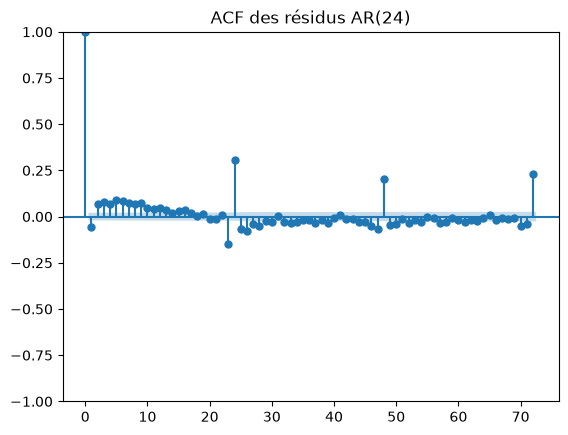

In [14]:
import matplotlib.pyplot as plt
from statsmodels.graphics.tsaplots import plot_acf

plot_acf(residuals, lags=72)

plt.title("ACF des résidus AR(24)")
plt.show()

In [16]:
import numpy as np

def Q1_SimChemin(bg, s, phi, e, h):

    s = list(np.asarray(s).flatten())

    p = len(s)

    chemin = np.zeros(h)

    for i in range(h):

       
        pred = phi[0]

        for j in range(p):
            pred += phi[j+1] * s[-j-1]

        residu = bg.choice(e)
        
        futur = pred + residu

        chemin[i] = futur

      
        s.append(futur)

    return chemin

Coefficients estimés :
[ 6.17161737e-01  1.14655570e+00 -3.62307439e-01  4.81448548e-02
  1.82048083e-02 -5.14513728e-02  1.77958208e-02 -1.37829258e-02
 -8.19180964e-03 -2.83025297e-04  5.40527243e-02 -2.03787144e-02
 -2.59608872e-02  1.96303383e-02  1.72997359e-02 -4.48336581e-02
  6.46957807e-03  2.49123687e-03 -1.88946497e-03 -1.03915995e-02
  4.46117746e-02 -6.99824600e-03 -2.39806338e-02  3.04677785e-01
 -1.30768506e-01]


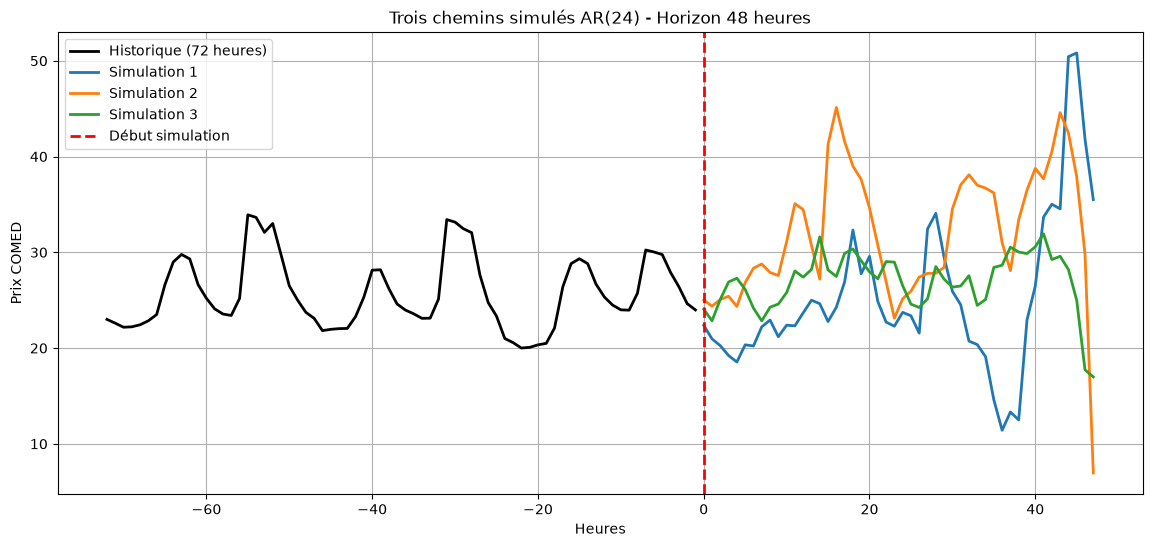

In [20]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt


df = pd.read_csv("PJM.csv")

df.columns = df.columns.str.strip()

price = pd.to_numeric(df["Zonal COMED price"], errors="coerce")

price_2018 = price.iloc[-8760:].reset_index(drop=True)


def Q1_AREstimate(s, p):

    s = np.asarray(s).flatten()

    T = len(s)

    y = s[p:]

    X = np.ones((T - p, p + 1))

    for j in range(1, p + 1):
        X[:, j] = s[p - j:T - j]

    phi = np.linalg.inv(X.T @ X) @ (X.T @ y)

    yhat = X @ phi

    residuals = y - yhat

    return phi, residuals


phi, residuals = Q1_AREstimate(price_2018.values, 24)

print("Coefficients estimés :")
print(phi)



def Q1_SimChemin(bg, s, phi, e, h):

    s = list(np.asarray(s).flatten())

    p = len(s)

    path = np.zeros(h)

    for i in range(h):

        forecast = phi[0]

        for j in range(p):
            forecast += phi[j + 1] * s[-j - 1]

        bootstrap_residual = bg.choice(e)

        future_value = forecast + bootstrap_residual

        path[i] = future_value

        s.append(future_value)

    return path


bg = np.random.default_rng(123)

s0 = price_2018.iloc[-24:].values

h = 48

path1 = Q1_SimChemin(bg, s0.copy(), phi, residuals, h)
path2 = Q1_SimChemin(bg, s0.copy(), phi, residuals, h)
path3 = Q1_SimChemin(bg, s0.copy(), phi, residuals, h)


history = price_2018.iloc[-72:].values

x_history = np.arange(-72, 0)
x_future = np.arange(0, h)


plt.figure(figsize=(14, 6))

plt.plot(
    x_history,
    history,
    color="black",
    linewidth=2,
    label="Historique (72 heures)"
)

plt.plot(
    x_future,
    path1,
    linewidth=2,
    label="Simulation 1"
)

plt.plot(
    x_future,
    path2,
    linewidth=2,
    label="Simulation 2"
)

plt.plot(
    x_future,
    path3,
    linewidth=2,
    label="Simulation 3"
)

plt.axvline(
    x=0,
    color="red",
    linestyle="--",
    linewidth=2,
    label="Début simulation"
)

plt.title("Trois chemins simulés AR(24) - Horizon 48 heures")
plt.xlabel("Heures")
plt.ylabel("Prix COMED")
plt.legend()
plt.grid(True)

plt.show()


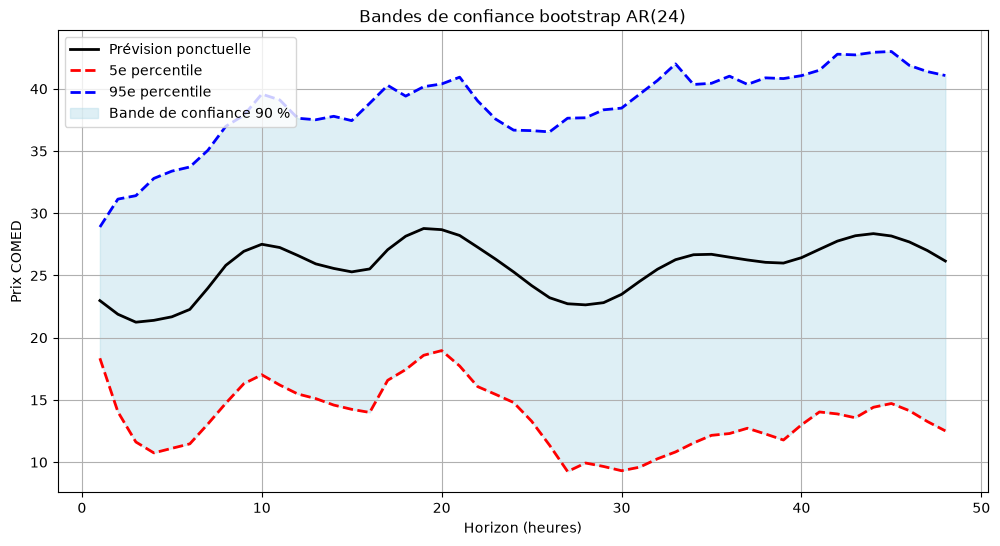

Largeur bande horizon 1  : 10.545820722874883
Largeur bande horizon 24 : 21.8836050103748
Largeur bande horizon 48 : 28.550106584974138


In [21]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt


df = pd.read_csv("PJM.csv")
df.columns = df.columns.str.strip()

price = pd.to_numeric(df["Zonal COMED price"], errors="coerce")

price_2018 = price.iloc[-8760:].reset_index(drop=True)


def Q1_AREstimate(s, p):

    s = np.asarray(s).flatten()

    T = len(s)

    y = s[p:]

    X = np.ones((T - p, p + 1))

    for j in range(1, p + 1):
        X[:, j] = s[p - j:T - j]

    phi = np.linalg.inv(X.T @ X) @ (X.T @ y)

    fitted = X @ phi

    residuals = y - fitted

    return phi, residuals


def Q1_SimChemin(bg, s, phi, e, h):

    s = list(np.asarray(s).flatten())

    p = len(s)

    path = np.zeros(h)

    for i in range(h):

        forecast = phi[0]

        for j in range(p):

            forecast += phi[j + 1] * s[-j - 1]

        shock = bg.choice(e)

        future_value = forecast + shock

        path[i] = future_value

        s.append(future_value)

    return path


def PointForecast(s, phi, h):

    s = list(np.asarray(s).flatten())

    p = len(s)

    forecasts = np.zeros(h)

    for i in range(h):

        pred = phi[0]

        for j in range(p):

            pred += phi[j + 1] * s[-j - 1]

        forecasts[i] = pred

        s.append(pred)

    return forecasts


def Q1_SimBandes(bg, s, p, h, N):

    phi, residuals = Q1_AREstimate(s, p)

    s0 = s[-p:]

    simulations = np.zeros((N, h))

    for i in range(N):

        simulations[i, :] = Q1_SimChemin(
            bg,
            s0.copy(),
            phi,
            residuals,
            h
        )

    return simulations


p = 24
h = 48
N = 1000

bg = np.random.default_rng(123)


phi, residuals = Q1_AREstimate(
    price_2018.values,
    p
)

simulations = Q1_SimBandes(
    bg,
    price_2018.values,
    p,
    h,
    N
)


initial_state = price_2018.values[-p:]

point_forecast = PointForecast(
    initial_state,
    phi,
    h
)


lower_band = np.percentile(
    simulations,
    5,
    axis=0
)

upper_band = np.percentile(
    simulations,
    95,
    axis=0
)

median_sim = np.percentile(
    simulations,
    50,
    axis=0
)


x = np.arange(1, h + 1)

plt.figure(figsize=(12, 6))

plt.plot(
    x,
    point_forecast,
    color="black",
    linewidth=2,
    label="Prévision ponctuelle"
)

plt.plot(
    x,
    lower_band,
    color="red",
    linestyle="--",
    linewidth=2,
    label="5e percentile"
)

plt.plot(
    x,
    upper_band,
    color="blue",
    linestyle="--",
    linewidth=2,
    label="95e percentile"
)

plt.fill_between(
    x,
    lower_band,
    upper_band,
    color="lightblue",
    alpha=0.4,
    label="Bande de confiance 90 %"
)

plt.title("Bandes de confiance bootstrap AR(24)")
plt.xlabel("Horizon (heures)")
plt.ylabel("Prix COMED")
plt.legend()
plt.grid(True)

plt.show()


band_width = upper_band - lower_band

print("Largeur bande horizon 1  :", band_width[0])
print("Largeur bande horizon 24 :", band_width[23])
print("Largeur bande horizon 48 :", band_width[47])

In [24]:
import pandas as pd
import numpy as np
from scipy import stats


df = pd.read_csv("PJM.csv")
df.columns = df.columns.str.strip()

price = pd.to_numeric(
    df["Zonal COMED price"],
    errors="coerce"
)

price_2018 = price.iloc[-8760:].reset_index(drop=True)



def Q1_ARForecast(s, phi):

    s = np.asarray(s).flatten()
    phi = np.asarray(phi).flatten()

    p = len(s)

    forecast = phi[0]

    for j in range(p):
        forecast += phi[j + 1] * s[p - j - 1]

    return forecast


def Q1_AREstimate(s, p):

    s = np.asarray(s).flatten()

    T = len(s)

    y = s[p:]

    X = np.ones((T - p, p + 1))

    for j in range(1, p + 1):
        X[:, j] = s[p - j:T - j]


    phi = np.linalg.lstsq(X, y, rcond=None)[0]

    fitted = X @ phi

    residuals = y - fitted

    return phi, residuals


p_hourly = 24

forecast_hourly = []
actual_hourly = []


for t in range(200, len(price_2018) - 1):

    train = price_2018.iloc[:t].values

    phi, residuals = Q1_AREstimate(
        train,
        p_hourly
    )

    s_recent = train[-p_hourly:]

    forecast = Q1_ARForecast(
        s_recent,
        phi
    )

    forecast_hourly.append(forecast)

    actual_hourly.append(
        price_2018.iloc[t]
    )

forecast_hourly = np.array(forecast_hourly)
actual_hourly = np.array(actual_hourly)


num_days = len(forecast_hourly) // 24

forecast_daily_from_hourly = (
    forecast_hourly[:24 * num_days]
    .reshape(num_days, 24)
    .mean(axis=1)
)

actual_daily_from_hourly = (
    actual_hourly[:24 * num_days]
    .reshape(num_days, 24)
    .mean(axis=1)
)



daily_price = (
    price_2018.values
    .reshape(-1, 24)
    .mean(axis=1)
)


p_daily = 6

forecast_AR6 = []
actual_AR6 = []

for t in range(30, len(daily_price) - 1):

    train = daily_price[:t]

    phi_daily, residuals_daily = (
        Q1_AREstimate(
            train,
            p_daily
        )
    )

    s_recent = train[-p_daily:]

    forecast = Q1_ARForecast(
        s_recent,
        phi_daily
    )

    forecast_AR6.append(forecast)

    actual_AR6.append(
        daily_price[t]
    )

forecast_AR6 = np.array(forecast_AR6)
actual_AR6 = np.array(actual_AR6)



m = min(
    len(actual_daily_from_hourly),
    len(forecast_daily_from_hourly),
    len(forecast_AR6)
)

actual = actual_daily_from_hourly[-m:]

forecast_hourly_daily = (
    forecast_daily_from_hourly[-m:]
)

forecast_AR6 = forecast_AR6[-m:]



err_hourly = actual - forecast_hourly_daily

err_AR6 = actual - forecast_AR6



print("Nombre d'observations :", m)

print("RMSE AR(24) agrégé =",
      np.sqrt(np.mean(err_hourly**2)))

print("RMSE AR(6) journalier =",
      np.sqrt(np.mean(err_AR6**2)))


print("\nVecteurs prêts pour le DM test:")

print("err_hourly.shape =", err_hourly.shape)
print("err_AR6.shape    =", err_AR6.shape)

def Q2_DM(e1, e2):

    # pertes quadratiques
    d = e1**2 - e2**2

    n = len(d)

    d_bar = np.mean(d)

    var_d = np.var(d, ddof=1)

    DM = d_bar / np.sqrt(var_d / n)

    p_value = 2 * (1 - stats.norm.cdf(abs(DM)))

    return DM, p_value

DM_stat, p_value = Q2_DM(
    err_hourly,
    err_AR6
)

print("DM statistic =", DM_stat)
print("p-value =", p_value)



Nombre d'observations : 334
RMSE AR(24) agrégé = 0.7642756824087383
RMSE AR(6) journalier = 4.819351924565632

Vecteurs prêts pour le DM test:
err_hourly.shape = (334,)
err_AR6.shape    = (334,)
DM statistic = -11.440951224526508
p-value = 0.0
